## Entrega #2 - Juan José Zuluaga y Juan Sebastián Pacheco

En la industria cafetera, la estimación precisa de la madurez de los granos es un factor clave para optimizar la producción y cumplir con los compromisos de los contratos de futuro. La Federación Nacional de Cafeteros y los productores dependen de estas estimaciones para planificar la cosecha, gestionar la logística y asegurar la calidad del café exportado. Sin embargo, los métodos tradicionales de muestreo manual pueden ser imprecisos y costosos en términos de tiempo y recursos.

Este taller presenta un modelo de aprendizaje no supervisado capaz de contar los granos maduros en la imágen de un cafeto, proporcionando una herramienta automatizada para mejorar la precisión en la estimación de producción. El proceso que implementaremos consta de tres etapas fundamentales:

1. Segmentación de la imagen: Identificaremos los píxeles rojos correspondientes a los granos maduros, separándolos del fondo y de otros elementos de la planta.

2. Filtrado y detección de bordes: Aplicaremos técnicas de procesamiento de imágenes para diferenciar los granos entre sí, asegurando una correcta identificación de cada unidad individual.

3. !!!! Conteo de granos: Utilizaremos detección de características u otros modelos adecuados para contar de manera precisa la cantidad de granos maduros en la imagen.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

### Preprocesamiento de imagenes

In [ ]:
image_folder = "../imagenes/crudas"
image_files = os.listdir(image_folder)

for img_name in image_files:
    img_path = os.path.join(image_folder, img_name)

    # Reduccion de la resolución a un 30%
    img = cv2.imread(img_path)
    scale_percent = 0.4 
    width = int(img.shape[1] * scale_percent)
    height = int(img.shape[0] * scale_percent)
    img_rescaled = cv2.resize(img, (width, height), interpolation=cv2.INTER_AREA)

    # Aplicar Suavizado Gaussiano
    img_blurred = cv2.GaussianBlur(img_rescaled, (5, 5), 0)

    
    # Convertir a escala de grises para filtro de bordes
    gray = cv2.cvtColor(img_blurred, cv2.COLOR_BGR2GRAY)
    
    # Aplicar filtro Sobel
    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)  
    sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)  
    edges = cv2.magnitude(sobelx, sobely)  
    edges = np.uint8(edges)  

    #Normalizar bordes para que tengan valores entre 0 y 255
    edges = cv2.normalize(edges, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)

    # Crear máscara de bordes
    mask = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)  # Convertir a 3 canales (RGB)

    # 📌 Combinación de la imagen original con los bordes resaltados
    img_enhanced = cv2.addWeighted(img_rescaled, 1, mask, 0.5, 0)  # Mezcla con pesos
    # Guardar imagen preprocesada
    output_path = os.path.join("../imagenes/procesadas", img_name)
    cv2.imwrite(output_path, img_enhanced)

### Segmentación

Segmentar cada imagen en dos o más clusters de tal manera que en un cluster queden separados todos los granos maduros

El punto despues del primer pico donde la segunda derivada empieza a estabilizarse alrededor de 0 es:  136


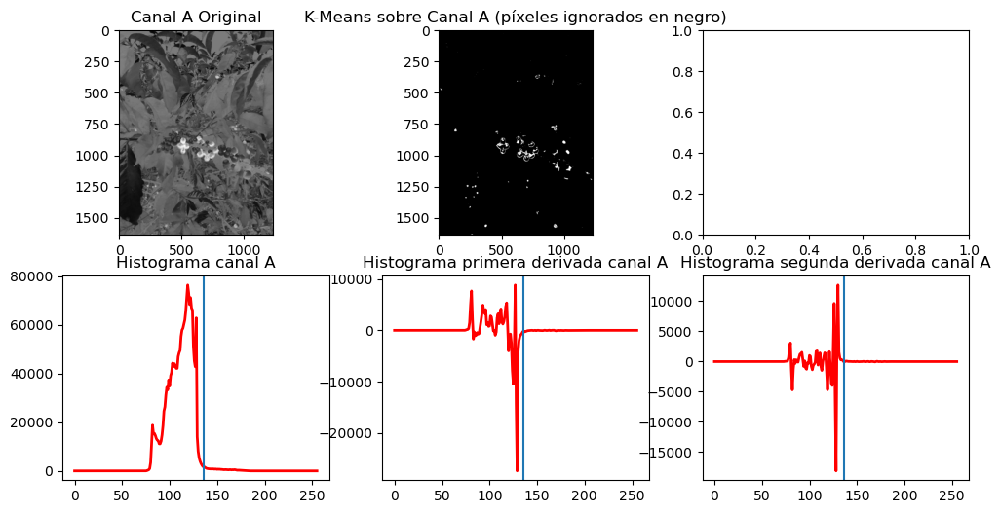

In [73]:
image_folder = "../imagenes/procesadas"
image_files = os.listdir(image_folder)

img_path = os.path.join(image_folder, image_files[2])
img = cv2.imread(img_path)

lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
L, A, B = cv2.split(lab)

# considera para kmeans solamente los pixeles con más intensidad que el umbral
# !!! explicar como escojimos el umbral
hist = cv2.calcHist([A], [0], None, [256], [0, 256]).flatten()
first_derivative = np.gradient(hist)
second_derivative = np.gradient(first_derivative)

min_thresh = np.argmax(hist)+np.argmax(second_derivative[np.argmax(hist):])
for j in range(len(second_derivative)):
    if j > min_thresh and second_derivative[j] < 70:
        thresh = j
        break
print("El punto despues del primer pico donde la segunda derivada empieza a estabilizarse alrededor de 0 es: ", thresh)
mask = A >= thresh 

# Aplicar K-Means solo a los píxeles válidos (mayores que el umbral)
valid_pixels = A[mask].reshape(-1, 1).astype(np.float32)

K = 2
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
_, labels, centers = cv2.kmeans(valid_pixels, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

clustered_img = np.zeros_like(A, dtype=np.uint8)
clustered_img[mask] = (labels.flatten() * (255 // (K - 1)))  # Normaliza a 0 y 255

fig, ax = plt.subplots(2, 3, figsize=(12, 6))

ax[0][0].imshow(A, cmap="gray")
ax[0][0].set_title("Canal A Original")

ax[0][1].imshow(clustered_img, cmap="gray")
ax[0][1].set_title("K-Means sobre Canal A (píxeles ignorados en negro)")

ax[1][0].plot(hist, color="red", linewidth=2)
ax[1][0].axvline(x=thresh)
ax[1][0].set_title("Histograma canal A")

ax[1][1].plot(first_derivative, color="red", linewidth=2)
ax[1][1].axvline(x=thresh)
ax[1][1].set_title("Histograma primera derivada canal A")

ax[1][2].plot(second_derivative, color="red", linewidth=2)
ax[1][2].axvline(x=thresh)
ax[1][2].set_title("Histograma segunda derivada canal A")

plt.show()

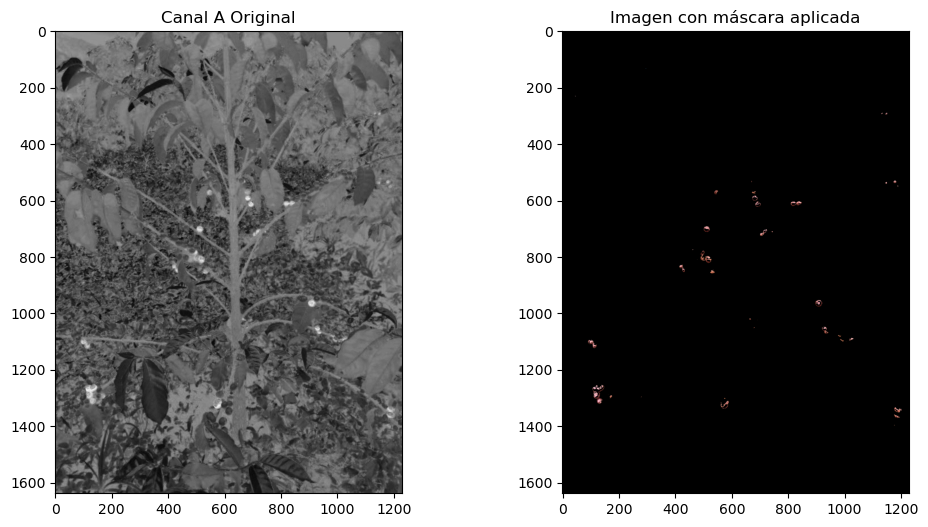

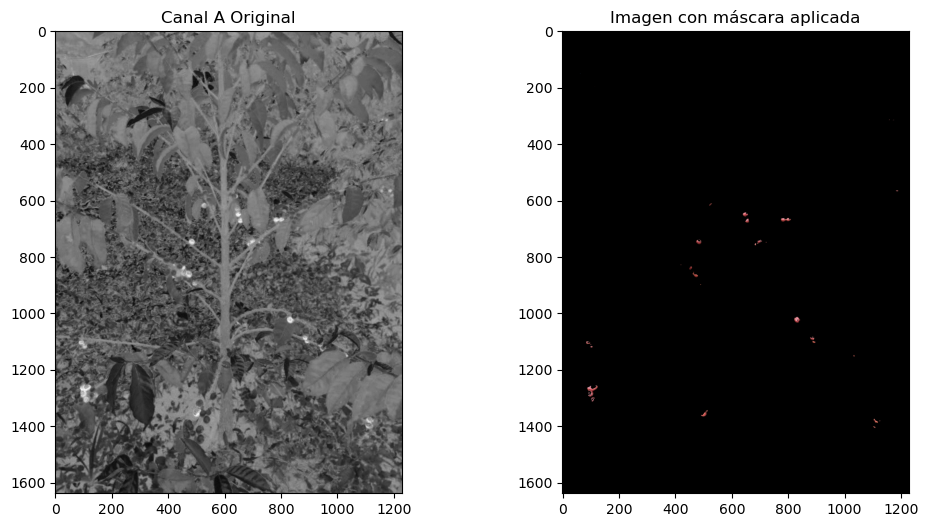

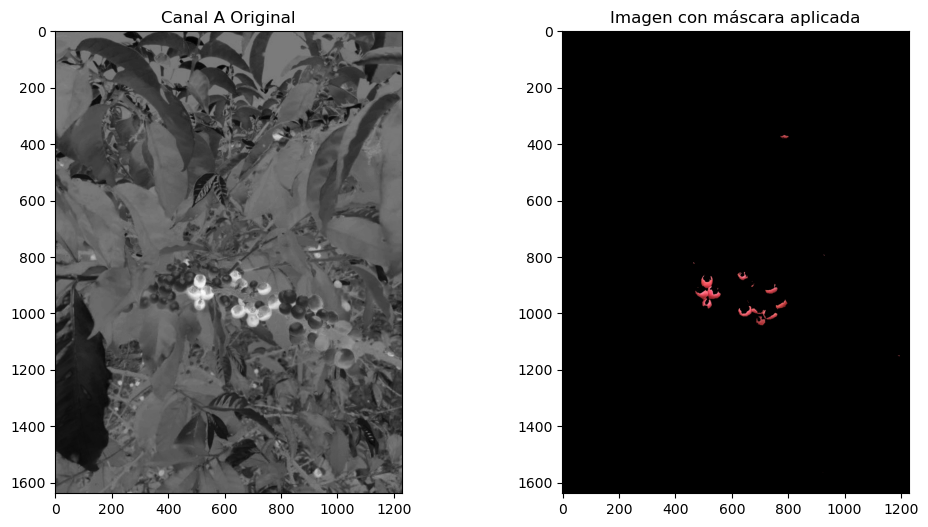

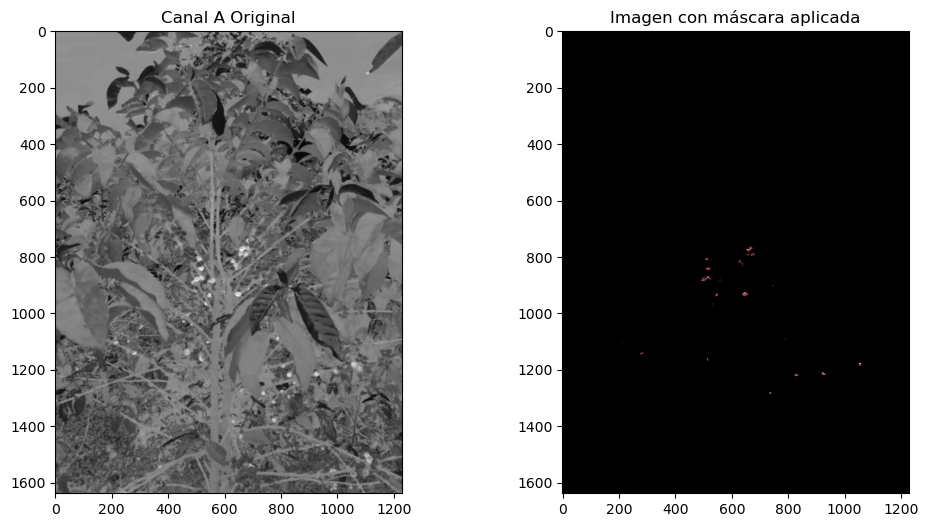

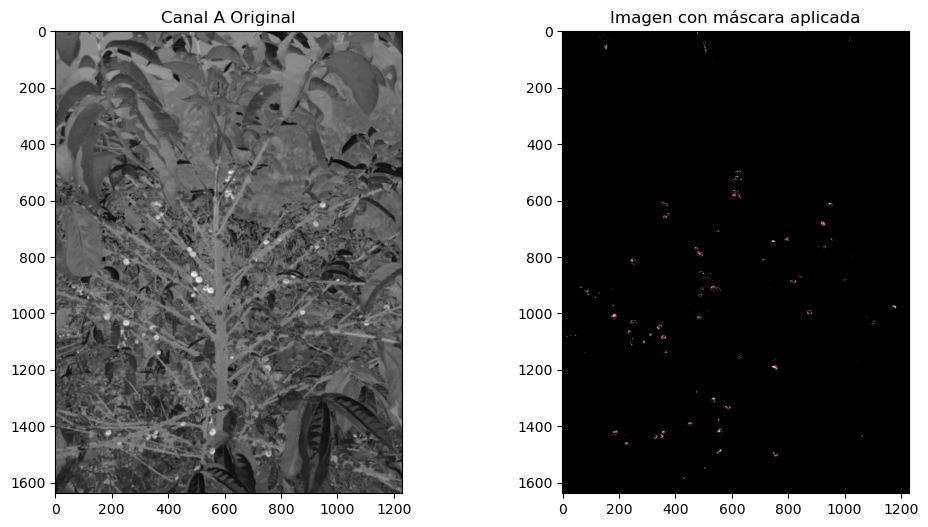

...

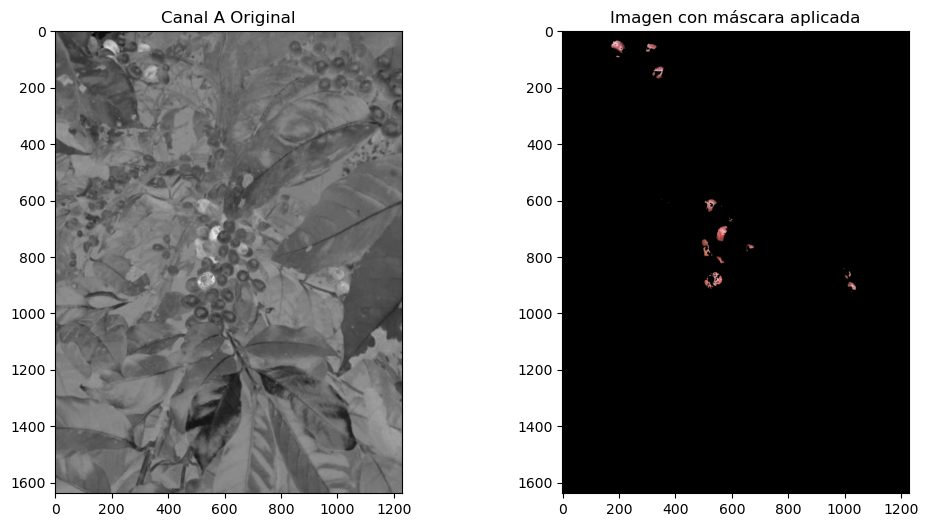

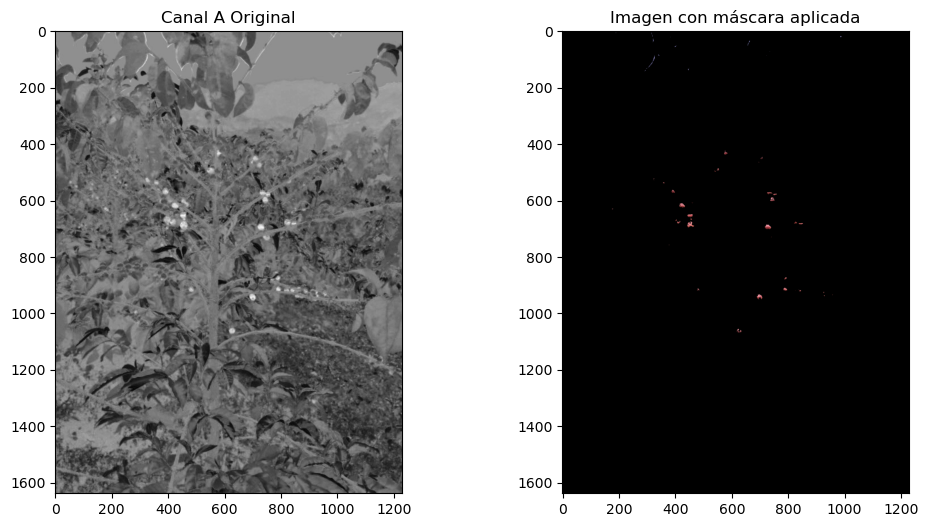

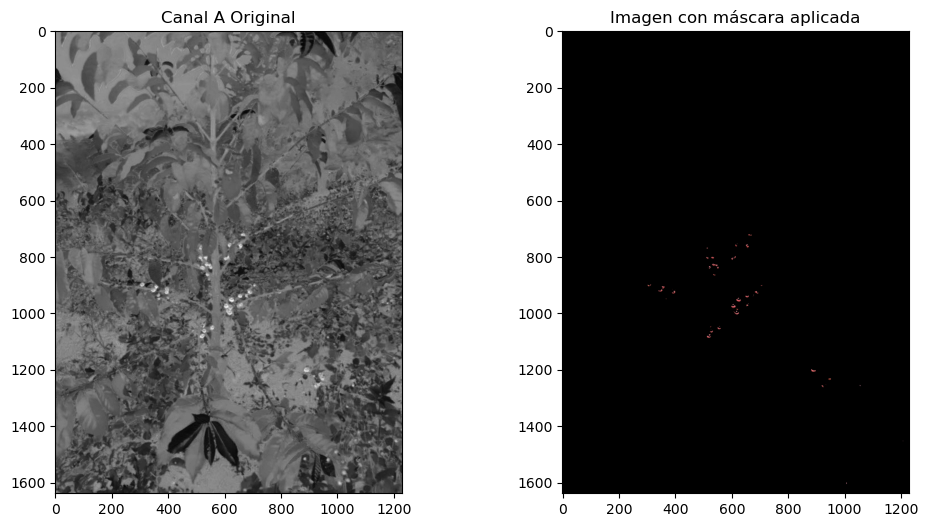

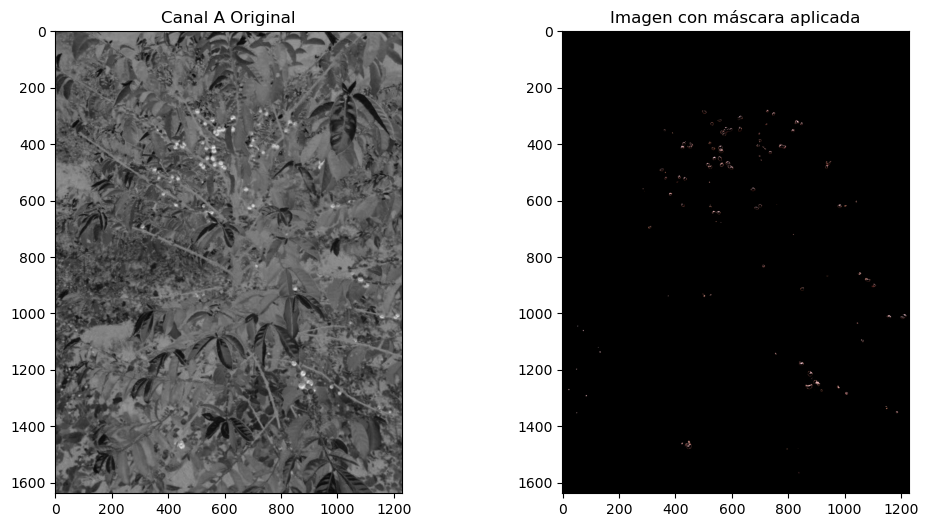

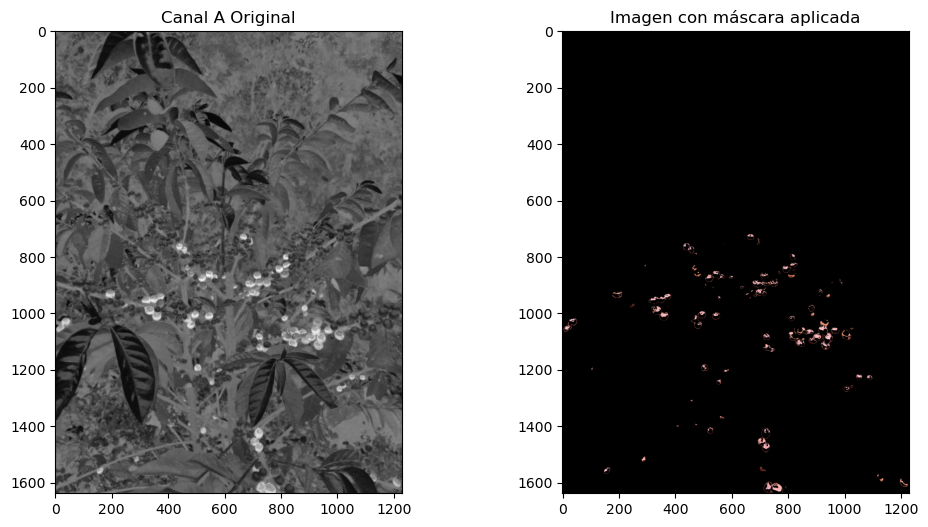

In [ ]:
image_folder = "../imagenes/procesadas"
image_files = os.listdir(image_folder)

for img_name in image_files:
    img_path = os.path.join(image_folder, img_name)
    img = cv2.imread(img_path)
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab)
    
    # 138 es el umbral que se ha encontrado para el canal A
    mask = A >= 138   
    A_normal = A / np.sum(A)

    # Aplicar K-Means solo a los píxeles mayores que el umbral
    valid_pixels = A_normal[mask].reshape(-1, 1).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(valid_pixels, 2, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    
    # Crear una máscara con los clusters grano maduro/otra cosa
    clustered_img = np.zeros_like(A, dtype=np.uint8)
    clustered_img[mask] = labels.flatten()
    
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    
    ax[0].imshow(A_normal, cmap="gray")
    ax[0].set_title("Canal A Original")


    # Aplicar la máscara clustered_img a la imagen original
    masked_img = img.copy()
    masked_img[clustered_img == 0] = [0, 0, 0]

    ax[1].imshow(cv2.cvtColor(masked_img, cv2.COLOR_BGR2RGB))
    ax[1].set_title("Imagen con máscara aplicada")

    output_path = os.path.join("../imagenes/maduros_segmentados", img_name)
    cv2.imwrite(output_path, masked_img)

    plt.show()

Conteo de los granos, aplicando una deteccion de bordes y luego se cuentan los contornos.

Número de granos maduros detectados: 45


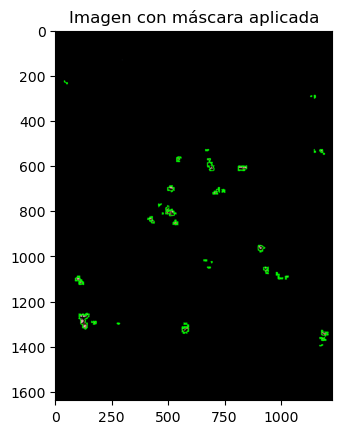

Número de granos maduros detectados: 33


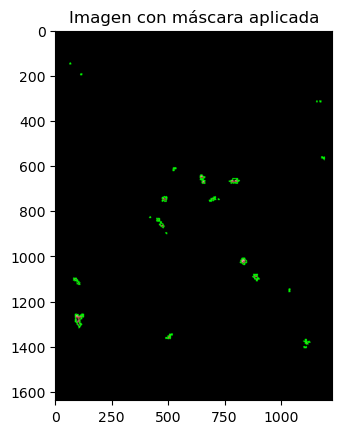

Número de granos maduros detectados: 20


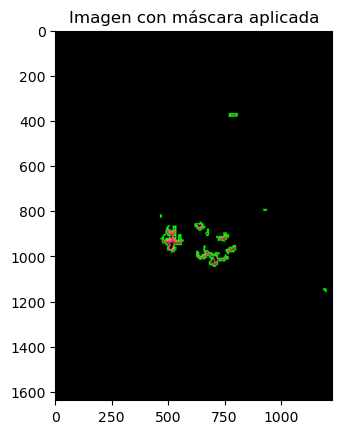

Número de granos maduros detectados: 32


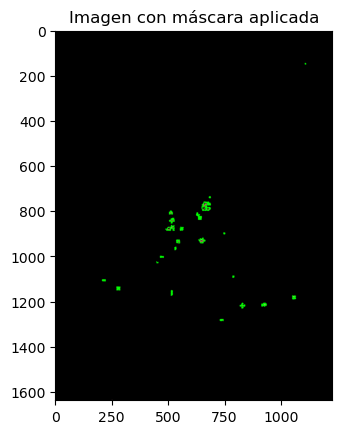

Número de granos maduros detectados: 107


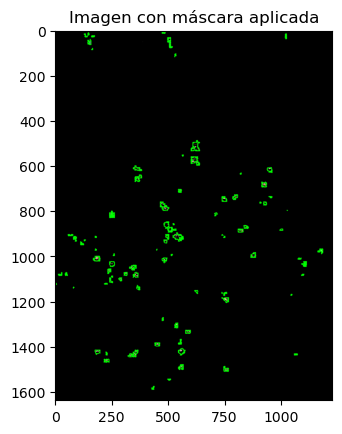

Número de granos maduros detectados: 199


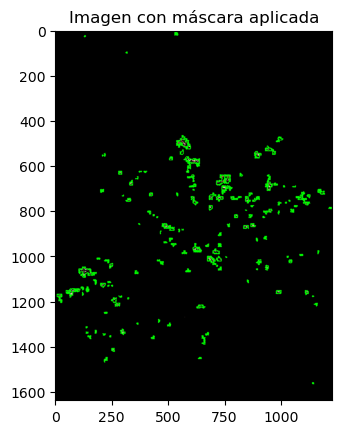

Número de granos maduros detectados: 181


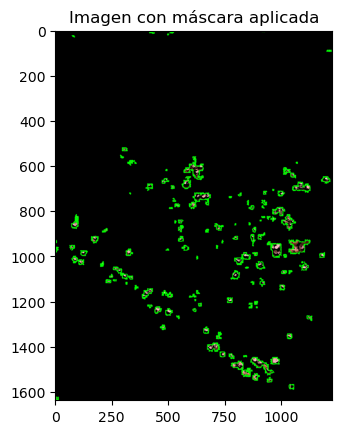

Número de granos maduros detectados: 210


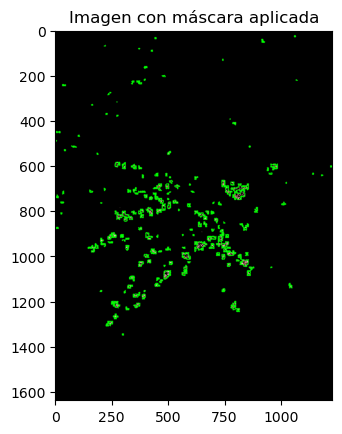

Número de granos maduros detectados: 152


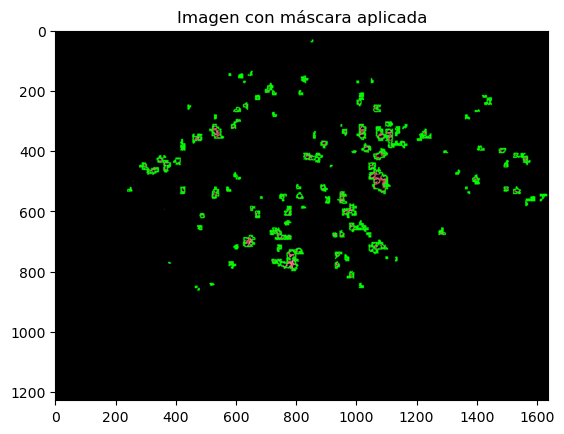

Número de granos maduros detectados: 101


KeyboardInterrupt: 

In [115]:
image_folder = "../imagenes/maduros_segmentados"
image_files = os.listdir(image_folder)

for img_name in image_files:
    img_path = os.path.join(image_folder, img_name)
    img = cv2.imread(img_path)
    mask = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Filtrar por tamaño mínimo (para evitar ruidos)
    min_area = 1.5  # Ajusta según el tamaño de los granos
    filtered_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > min_area]

    # Contar los granos maduros
    num_granos = len(filtered_contours)
    print(f"Número de granos maduros detectados: {num_granos}")

    # Dibujar los contornos sobre la imagen original
    cv2.drawContours(img, filtered_contours, -1, (0, 255, 0), 2)

    # Guardar o mostrar resultado
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Imagen con máscara aplicada")

    plt.show()